# Scoped SPATA2-inspired spatial validation

The independent package now follows the OmicVerse DBSCAN default. These are **3,639 real retained spots** from DLPFC 151673 plus **five deliberately planted isolated controls**. The control coordinates are artificial and are never interpreted as tissue. Nine native spots are flagged; without ground-truth labels those are candidate outliers, not established artifacts.

The comparison is to R `dbscan` with the same epsilon and minimum-neighbor rule. This tests the density-based outlier kernel only, not full SPATA2 object semantics, concave outlines, tissue fragments, annotations, trajectories or gradient screening. The package still uses a single convex outline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from anndata import AnnData
from scipy import sparse
import spata2py
f = np.load('data/dlpfc_coords.npz')
a = AnnData(sparse.csr_matrix((len(f['coords']), 1)))
a.obsm['spatial'] = f['coords']
flags = spata2py.identify_spatial_outliers(a).to_numpy()
np.testing.assert_array_equal(flags, f['expected'].astype(bool))
print({'native_flags': int(flags[:-5].sum()), 'planted_detected': int(flags[-5:].sum()), 'R_disagreements': int((flags != f['expected']).sum())})

{'native_flags': 9, 'planted_detected': 5, 'R_disagreements': 0}


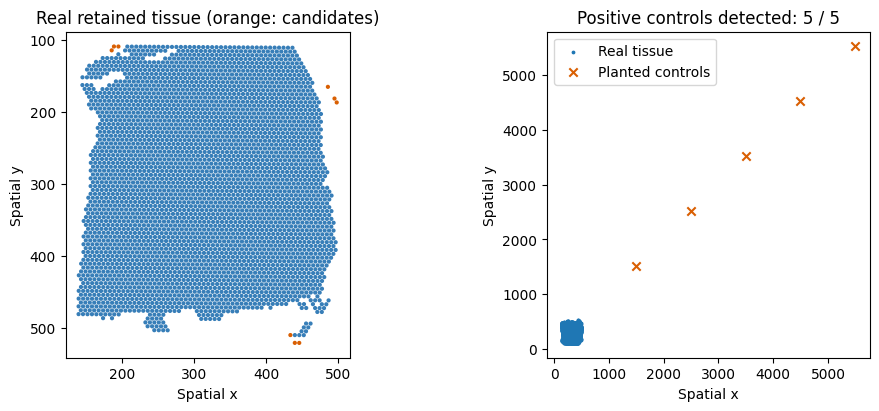

In [2]:
fig, axes = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
xy = f['coords']
axes[0].scatter(xy[:-5,0],xy[:-5,1],c=np.where(flags[:-5], '#d95f02','#377eb8'),s=4)
axes[0].set(title='Real retained tissue (orange: candidates)',xlabel='Spatial x',ylabel='Spatial y',aspect='equal')
axes[0].invert_yaxis()
axes[1].scatter(xy[:-5,0],xy[:-5,1],s=3,label='Real tissue')
axes[1].scatter(xy[-5:,0],xy[-5:,1],marker='x',c='#d95f02',label='Planted controls')
axes[1].set(title='Positive controls detected: 5 / 5',xlabel='Spatial x',ylabel='Spatial y',aspect='equal')
axes[1].legend()
plt.show()